<a href="https://colab.research.google.com/github/yulianacm/Investigacion-de-operaciones/blob/main/Tutorial1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <font color="pink"> **Tutorial NetworkX 1**

En este cuaderno se describe la solución de tres problemas de redes por distintos modelos:
**árbol de expansión mínima, la ruta más corta y el modelo de flujo de fluido máximo**.

El contenido de este tutorial está basado en la documentación de https://networkx.org/en/.

In [68]:
import networkx as nx
import matplotlib.pyplot as plt

# <font color="coral"> *Árbol de expansión mínima*

Realizar el árbol de expansión mínima para la red siguiente:


In [69]:
G = nx.DiGraph()
G.add_nodes_from([1, 2, 3, 4, 5, 6, 7])

Agregamos todos los nodos y arcos de nuestro ejercicio.

In [70]:
G.add_edges_from([
    (1, 3, {'weight': 1}) ,
    (1, 2, {'weight': 5}) ,
    (2, 5, {'weight': 1}) ,
    (3, 2, {'weight': 2}) ,
    (2, 6, {'weight': 6}) ,
    (2, 4, {'weight': 7}) ,
    (3, 4, {'weight': 6}) ,
    (3, 5, {'weight': 7}) ,
    (5, 4, {'weight': 3}) ,
    (5, 6, {'weight': 5}) ,
    (5, 7, {'weight': 9}) ,
    (4, 6, {'weight': 4}) ,
    (4, 3, {'weight': 7}) ,
    (4, 7, {'weight': 6}) ,
    (6, 2, {'weight': 7}) ,
    (6, 7, {'weight': 2}) ,
])

Describimos las coordenadas de los nodos, para saber sus respectivas ubicaciones:

In [71]:
pos= {
    1: (1, 1),
    2: (2, 2),
    3: (2, 0),
    4: (3.2, 1.3),
    5: (4, 0),
    6: (4, 2),
    7: (5, 1)
}
plt.figure(figsize=(12, 15))

<Figure size 1200x1500 with 0 Axes>

<Figure size 1200x1500 with 0 Axes>

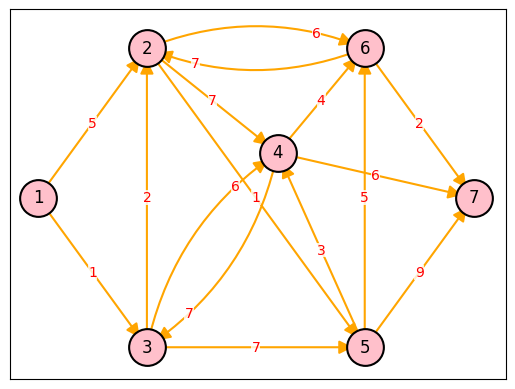

In [72]:
#Nodos
nx.draw_networkx_nodes(G, pos, node_size=700, node_color="pink", edgecolors="black",
                        linewidths=1.5)
nx.draw_networkx_labels(G, pos, font_size=12, font_weight="normal")
#Aristas
contador = 0
for u, v, data in G.edges(data=True):
    contador += 1
    if G.has_edge(v,u):
        if u ==v:
            rad=0.2
            pos_label=(0.3)
        else:
            rad= -0.2
            pos_label=(0.8)
    else:
        rad= 0.0
        pos_label=0.5

    nx.draw_networkx_edges(G, pos, edgelist=[(u,v)], edge_color="orange", width=1.5, arrowsize=20,
                            arrowstyle="-|>", connectionstyle=f"arc3, rad={rad}")

    nx.draw_networkx_edge_labels(G, pos, label_pos= pos_label, edge_labels={(u,v): data["weight"]},
                                  font_size=10, font_color="red", rotate=False, bbox=dict( facecolor="white", edgecolor="none", alpha=0.8, pad=0.2),
                                  connectionstyle=f"arc3, rad={rad}")

plt.show()

## **Pasos para un árbol de expansión:**
Tomamos k = {1, 2, 3, ... n} como el conjunto de nodos que hay en nuestra red.

$C_k$ = {Conjuntos de nodos ya conectados.}

$\overline{C_k}$= {Conjunto de nodos faltantes por conectar al árbol de expansión.}

Y estos "k" van avanzando de acuerdo a como van avanzando los nodos en el árbol de expansión, para esto tomamos la arista unida al nodo inicial, de <font color="orange"> menor </font> cantidad; siendo la ruta óptima.

Ahora indicamos el comando para generar el árbol de expansión mínima.

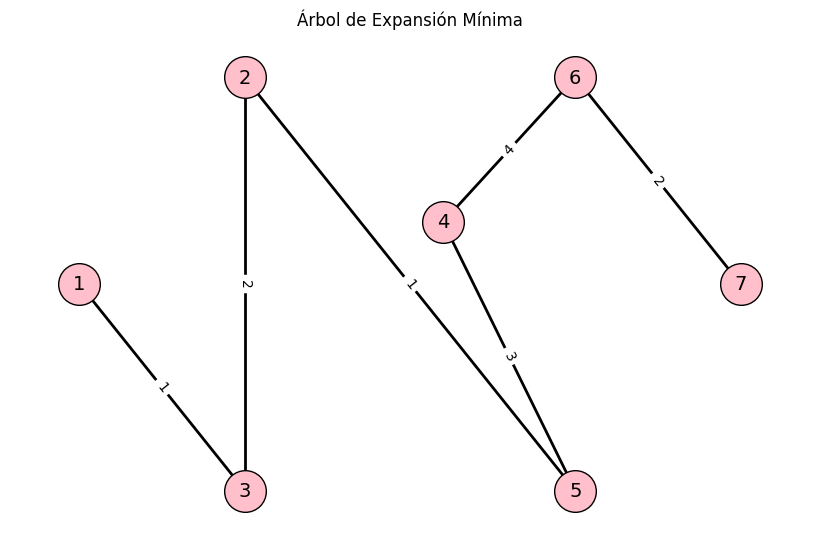

Ruta de 1 a 7: 1-> 3-> 2-> 5-> 4-> 6-> 7  (l= 13)


In [73]:
#Pasamos G a una red no dirigida para poder aplicar el árbol de expansión mínima
#Si una arista tiene dos pesos distintos (ida y vuelta), se queda con cualquiera de los dos.
G_nd = nx.Graph()
G_nd.add_nodes_from(G.nodes())
for u, v, w in G.edges(data="weight"):
    if G_nd.has_edge(u, v):
        G_nd[u][v]["weight"]= min(G_nd[u][v]["weight"], w)
    else:
        G_nd.add_edge(u, v, weight=w)
#Ahora ya podemos ingresar el comando para que nos brinde el árbol de expansión mínima
M= nx.minimum_spanning_tree(G_nd, weight="weight")

plt.figure(figsize=(8, 5))
nx.draw(M, pos, with_labels=True, node_color="pink",
        edgecolors="black", node_size=900, width=2,  font_size=14)
cantidades= nx.get_edge_attributes(M, "weight")
nx.draw_networkx_edge_labels(M, pos, edge_labels=cantidades, font_size=10)
plt.title(f"Árbol de Expansión Mínima")
plt.show()

#Ruta de 1 a 7
ruta= nx.shortest_path(M, source=1, target=7, weight="weight")
distancia= nx.shortest_path_length(M, source=1, target=7, weight="weight")
print(f"Ruta de 1 a 7: {'-> '.join(map(str, ruta))}  (l= {distancia})")

# <font color="coral"> *Ruta más corta*

## **Algoritmo:**

1.   <font color="orange"> Objetivo de la n-ésima iteración: </font> Encontrar el n-ésimo nodo más cercano al origen y así sucesivamente hasta llegar al destino.
2.  <font color="orange"> Datos de la n-ésima iteración: </font> n-1 nodos más cercanos al origen, incluidas su ruta más corta y la distancia desde el origen (son <font color="red"> nodos resueltos </font>; el resto son <font color="red"> nodos no resueltos </font>.
3. <font color="orange"> Candidatos a n-ésimo nodo más cercano: </font> Cada nodo no resuelto con conexión directa a uno o más no resueltos. Tomar el nodo no resuelto que tiene la ligadura más corta.





Ruta más corta de 1 a 7: 1 -> 3 -> 2 -> 6 -> 7
l total: 11


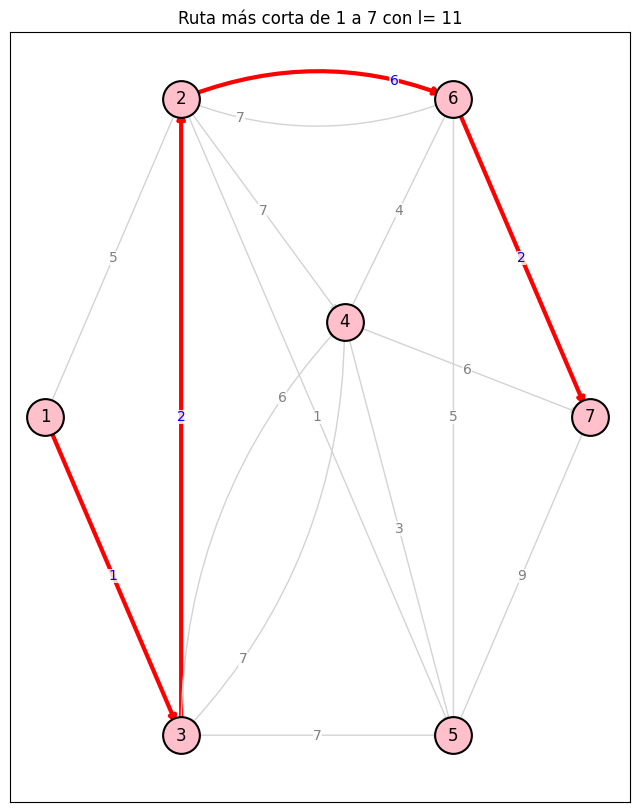

In [74]:
#Aquí sí usamos la red dirigida hecha al inicio, G.
origen= 1
destino= 7

ruta_corta =nx.shortest_path(G, source=origen, target=destino, weight="weight")
cant_menor =nx.shortest_path_length(G, source=origen, target=destino, weight="weight")

print(f"Ruta más corta de {origen} a {destino}: {' -> '.join(map(str, ruta_corta))}")
print(f"l total: {cant_menor}")

#Así se ve gráficamente
ruta_elegida= list(zip(ruta_corta[:-1], ruta_corta[1:]))

plt.figure(figsize=(8, 10))
nx.draw_networkx_nodes(G, pos, node_size=700, node_color="pink", edgecolors="black", linewidths=1.5)
nx.draw_networkx_labels(G, pos, font_size=12, font_weight="normal")

for u, v, data in G.edges(data=True):
    if G.has_edge(v, u):
        rad= -0.2 if u != v else 0.2
        pos_label= 0.8 if u != v else 0.3
    else:
        rad= 0.0
        pos_label= 0.5

    en_ruta= (u, v) in ruta_elegida
    color= "red" if en_ruta else "lightgray"
    ancho= 3 if en_ruta else 1

    nx.draw_networkx_edges(G, pos, edgelist=[(u, v)], edge_color=color, width=ancho, arrowsize=10,
                            arrowstyle="-|>", connectionstyle=f"arc3, rad={rad}")
    nx.draw_networkx_edge_labels(G, pos, label_pos=pos_label, edge_labels={(u, v): data["weight"]},
                                  font_size=10, font_color=("blue" if en_ruta else "gray"), rotate=False,
                                  bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=0.2),
                                  connectionstyle=f"arc3, rad={rad}")

plt.title(f"Ruta más corta de {origen} a {destino} con l= {cant_menor}")
plt.show()

# <font color="coral"> Método del flujo máximo

Hay información importante por saber del método, como:


1.   Todo flujo a través de una red dirtigida se origina en un nodo, el <font color="orange"> origen </font>, y termina en otro, que es el <font color="orange"> destino </font>.
2.   Los nodos restantes son <font color="orange"> nodos de transbordo </font>.
3. El flujo a través de un arco es solo en la dirección indicada por la flecha, su cantidad máxima se llama <font color="orange"> capacidad </font> del arco.
4. El objetivo es <font color="orange"> maximizar la cantidad total de flujo del origen al destino </font> (la que sale del origen o entra al destino.



Primero indicamos la ubicación de los nodos.

In [75]:
pos = {1: (0, 1),
       3: (1, 2),
       5: (2, 1),
       2: (0.5, 0),
       4: (1.5, 0),
}

Seguidos de los datos de las cantidades que viajan de nodo a nodo.

In [76]:
edges = [
    (1, 3, {"inicio": 14, "final": 0}),
    (1, 5, {"inicio": 4,  "final": 0}),
    (1, 2, {"inicio": 8,  "final": 0}),
    (3, 2, {"inicio": 10, "final": 5}),
    (3, 4, {"inicio": 9,  "final": 7}),
    (3, 5, {"inicio": 10, "final": 0}),
    (2, 4, {"inicio": 7,  "final": 6}),
    (2, 5, {"inicio": 6,  "final": 0}),
    (4, 5, {"inicio": 5,  "final": 0}),
]

Flujo máximo: 25


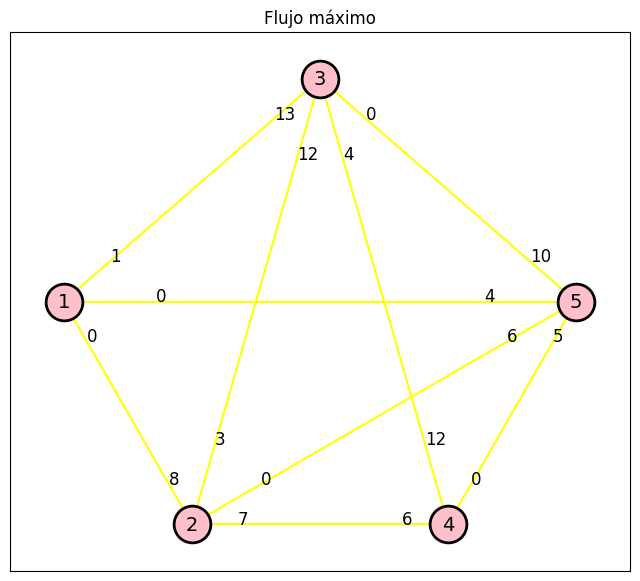

In [77]:
#Se cres la red dirigida para que el sistema reconozca el funcionamiento de los datos de inicio y fin
G_flujo= nx.DiGraph()
for u, v, datos in edges:
    G_flujo.add_edge(u, v, capacity=datos["inicio"])
    G_flujo.add_edge(v, u, capacity=datos["final"])

#Calculamos el flujo máximo
valor_flujo, flow_dict = nx.maximum_flow(G_flujo, 1, 5)
print("Flujo máximo:", valor_flujo)

#Construir la red residual
G_res = nx.Graph()
for u, v, datos in edges:
    cap_uv= datos["inicio"]
    cap_vu= datos["final"]
    flujo_uv= flow_dict[u][v]
    flujo_vu= flow_dict[v][u]

    res_uv= cap_uv - flujo_uv + flujo_vu
    res_vu= cap_vu - flujo_vu + flujo_uv

    G_res.add_edge(u, v, inicio=res_uv, final=res_vu)

#Graficar la red
fig, ax = plt.subplots(figsize=(8, 7))

nx.draw_networkx_edges(G_res, pos, ax=ax, width=1.5, edge_color="yellow")
nx.draw_networkx_nodes(G_res, pos, ax=ax, node_size=700, node_color="pink",
                        edgecolors="black", linewidths=2)
nx.draw_networkx_labels(G_res, pos, ax=ax, font_size=14)

for u, v, _ in edges:
    x1, y1= pos[u]
    x2, y2= pos[v]
    datos= G_res[u][v]

    lx1= x1 + 0.18 * (x2 - x1)
    ly1= y1 + 0.18 * (y2 - y1)
    ax.text(lx1, ly1, str(datos["inicio"]), fontsize=12)

    lx2= x2 + 0.18 * (x1 - x2)
    ly2= y2 + 0.18 * (y1 - y2)
    ax.text(lx2, ly2, str(datos["final"]), fontsize=12)

plt.title(f"Flujo máximo")
plt.show()